# Lab 2: Survival Analysis of Political Leaders' Time in Office

**Course:** QMSS GR5016 – Time Series, Panel Data & Forecasting <br>
**Author:** Savannah Estridge <br>
**Term:** Columbia University - Fall 2026 <br>

**Democracy VS Dictatorship Survival Analysis**

Survival analysis, also known as time-to-event analysis, is a set of statistical methods that address two related questions: how long it takes for an event to occur, and which factors increase or decrease the risk of that event. Using the Democracy and Dictatorship dataset (Cheibub, Gandhi & Vreeland, 2010), available in the lifelines package, I conduct a survival analysis of how long political leaders remain in office and which factors make them more or less likely to leave power.

In [39]:
#Install necessary packages
!pip install lifelines
!pip install lifelines[extras]

In [23]:
# Import dependencies
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MultipleLocator
from lifelines.datasets import load_dd
from lifelines import KaplanMeierFitter, CoxPHFitter, CoxTimeVaryingFitter, WeibullAFTFitter
from lifelines.utils import median_survival_times
from lifelines.statistics import logrank_test, multivariate_logrank_test
from lifelines.datasets import load_rossi
from matplotlib.ticker import PercentFormatter, MultipleLocator


In [40]:
# Load the Political Regimes dataset into a pandas DataFrame
df = load_dd()

# Inspect the first few rows and dimensions
print(f"Shape: {df.shape}")
df.head(3)

Shape: (1808, 12)


,ctryname,cowcode2,politycode,un_region_name,un_continent_name,ehead,leaderspellreg,democracy,regime,start_year,duration,observed
0,Afghanistan,700,700.0,Southern Asia,Asia,Mohammad Zahir Shah,Mohammad Zahir Shah.Afghanistan.1946.1952.Mona...,Non-democracy,Monarchy,1946,7,1
1,Afghanistan,700,700.0,Southern Asia,Asia,Sardar Mohammad Daoud,Sardar Mohammad Daoud.Afghanistan.1953.1962.Ci...,Non-democracy,Civilian Dict,1953,10,1
2,Afghanistan,700,700.0,Southern Asia,Asia,Mohammad Zahir Shah,Mohammad Zahir Shah.Afghanistan.1963.1972.Mona...,Non-democracy,Monarchy,1963,10,1


### Dataset Description

The Democracy and Dictatorship dataset contains **1,808 leader spells** across 12 variables, covering **200 countries** from 1946 (or a country's independence) through 2008. Each observation is one leader's continuous spell in office under a single regime type, which serves as the **unit of analysis** in this survival analysis.

For each spell, the data record a **duration** (`duration`, the number of years the leader remained in office) and an **event indicator (failure variable)** (`observed`), which shows whether the leader left office during the observation window (**1 = event**) or was **right-censored** (**0**). Censored spells belong to leaders who died in office or were still in office at the end of the observation window in 2008.

The dataset also includes **covariates** that may affect the **hazard** of leaving office. The main covariate is regime type: democracies are classified as parliamentary, mixed (semi-presidential), or presidential, and dictatorships as military, civilian, or monarchy. Additional covariates include the country's geographic region and continent.

This analysis examines how regime type affects how long political leaders remain in office. I hypothesize that leaders in non-democracies have longer survival times than leaders in democracies; that is, they face a lower hazard of leaving office. Democracies hold regular, competitive elections and often impose term limits, which create routine opportunities for leaders to lose or give up power. Leaders in non-democracies face fewer of these constraints.

Below is a data dictionary:

### Data Dictionary (`lifelines.datasets.load_dd`)

| Variable Name | Data Type | Role / Category | Coding Details & Allowed Values | Description |
| :--- | :--- | :--- | :--- | :--- |
| **`ctryname`** | String (`object`) | Identifier | Country name strings (e.g., `"Afghanistan"`, `"Argentina"`) | The name of the sovereign country being observed. |
| **`cowcode2`** | Integer (`int64`) | Country Code | Numeric Correlates of War (COW) codes | Standard political science numeric identifier for countries. |
| **`politycode`** | Float (`float64`) | Country Code | Numeric Polity IV country codes (contains missing/`NaN` values) | Alternative country code identifier from the Polity IV project dataset. |
| **`un_region_name`** | String (`object`) | Geographic | UN subregion strings (e.g., `"Southern Asia"`, `"Western Europe"`) | Geographic subregion classification defined by the United Nations. |
| **`un_continent_name`** | String (`object`) | Geographic | `"Africa"`, `"Americas"`, `"Asia"`, `"Europe"`, `"Oceania"` | Continent classification defined by the United Nations. |
| **`ehead`** | String (`object`) | Identifier | Leader name strings (e.g., `"Mohammad Zahir Shah"`) | The name of the effective head of government during the observed spell. |
| **`leaderspellreg`** | String (`object`) | Composite ID | Format: `[Leader Name].[Country].[Start Year].[End Year].[Regime]` | Unique string code mapping the leader, country, active years, and regime classification. |
| **`democracy`** | String (`object`) | Predictor (Binary) | `"Democracy"` or `"Non-democracy"` | Binary classification of whether the regime meets minimalist democratic criteria (contested elections and alternation in power). |
| **`regime`** | String (`object`) | Predictor (Categorical) | `"Parliamentary Dem"`, `"Mixed Dem"`, `"Presidential Dem"`, `"Civilian Dict"`, `"Military Dict"`, `"Royal Dict"` | Six-category institutional classification distinguishing democratic legislative systems and authoritarian ruler profiles. |
| **`start_year`** | Integer (`int64`) | Temporal | Calendar years (`1946` to `2008`) | The calendar year in which the specific leader/regime spell began. |
| **`duration`** | Integer (`int64`) | **Duration (Time)** | Positive integers (`1` to `47`) | **Time-to-event variable:** Total number of consecutive years the leader or regime remained in power during the study window. |
| **`observed`** | Integer (`int64`) | **Event Indicator** | `1` = Event observed (spell ended)<br>`0` = Right-censored (still in power at study cutoff) | **Status variable:** Code showing whether the leader/regime exited office during the tracking period (`1`) or remained active when observation ended in 2008 (`0`). |

<br>


### Survival Analysis Setup

| Component | Variable | Definition |
|---|---|---|
| **Unit of analysis** | `leaderspellreg` | One leader's continuous spell in office under a single regime type |
| **Observation window** | — | 1946–2008 (or from a country's independence) |
| **Start point (origin)** | `start_year` | Year the leader took office, when the leader enters the risk set |
| **Duration** | `duration` | Years the leader remained in office during the observation window |
| **Event (failure)** | `observed` = 1 | The leader left office during the observation window (1,468 spells) |
| **Right-censored** | `observed` = 0 | The leader died in office or was still in office in 2008 (340 spells, 18.8%) |
| **Left-truncated** | `start_year` = 1946 | Leaders already in office when observation began; their true durations may be understated (70 spells) |
| **Covariates** | `regime`, `democracy`, `un_continent_name` | Characteristics that may raise or lower the hazard of leaving office |

<br>

Survival analysis accounts for **censored data**: cases in which a subject was at risk of the event but did not experience it while under observation, either because the observation window closed first or because the subject left the risk set for another reason (E.G: they died while in office). In this dataset, leaders still in office at the end of 2008 and leaders who died in office are **right-censored**. Censored spells still contribute information: each counts as at risk for every year it was observed, then leaves the risk set without the event.

The **Risk window** is from 1946–2008, the years observed in the dataset (or from a country's independence). Each regime itself is at risk from their specific `start_year`.

### Kaplan Meier Model

In [49]:
# Define and fit Kaplain Meier model
T = df["duration"]
E = df["observed"]

kmf = KaplanMeierFitter()
survival = kmf.fit(durations=T, event_observed=E, label="All")

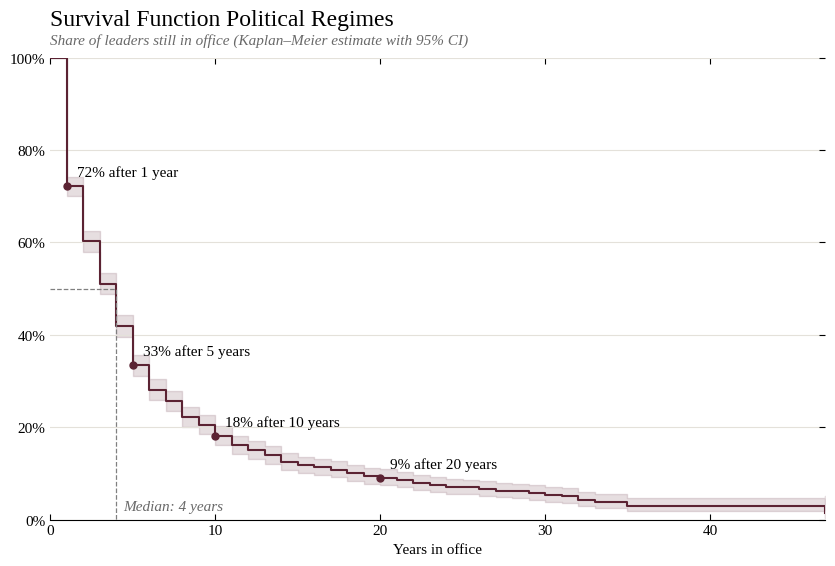

In [50]:
# Plot Kaplan Meier
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif"],
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "grid.color": "#e4e1da", "ytick.left": False})
LINE = "#5b2333"

# Curve and 95% CI
ax = kmf.plot_survival_function(color=LINE, ci_alpha=0.15, legend=False, figsize=(10, 6))

# Milestone labels
for yr in [1, 5, 10, 20]:
    s = float(kmf.predict(yr))
    ax.plot(yr, s, "o", color=LINE, ms=5)
    ax.annotate(f"{s:.0%} after {yr} year{'s' * (yr > 1)}", (yr, s),
                xytext=(7, 7), textcoords="offset points")

# Median
med = kmf.median_survival_time_
ax.plot([0, med, med], [0.5, 0.5, 0], color="gray", lw=0.9, ls="--")
ax.text(med + 0.4, 0.02, f"Median: {med:.0f} years", style="italic", color="dimgray")

# Axes and titles
ax.set(xlim=(0, kmf.timeline.max()), ylim=(0, 1), xlabel="Years in office")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.grid(True)
ax.xaxis.grid(False)
ax.set_title("Survival Function Political Regimes\n", loc="left", fontsize=17)
ax.text(0, 1.03, "Share of leaders still in office (Kaplan–Meier estimate with 95% CI)",
        transform=ax.transAxes, style="italic", color="dimgray")
plt.show()

The Kaplan–Meier curve above shows the estimated probability that a leader remains in office after t years (x-axis), and the shaded band shows the 95% confidence interval. Of 1,808 leader spells, 1,468 ended with the leader leaving office and 340 (18.8%) were censored. The median time in office is four years. Spells ranged from one year to 47 years.

In [45]:
# Table 1: Overview
n = len(kmf.durations)
events = int(kmf.event_observed.sum())
med_ci = median_survival_times(kmf.confidence_interval_)

overview = pd.DataFrame({"Value": [
    f"{n:,}",
    f"{events:,}",
    f"{n - events:,} ({(n - events) / n:.1%})",
    f"{kmf.median_survival_time_:.0f} years",
    f"{med_ci.iloc[0, 0]:.0f}–{med_ci.iloc[0, 1]:.0f} years"]},
    index=["Leader spells (N)", "Events (left office)", "Censored",
           "Median time in office", "95% CI for median"])

# Table 2: Survival at selected time points
ci = kmf.confidence_interval_survival_function_
rows = []
for t in [1, 2, 5, 10, 15, 20, 30]:
    rows.append({
        "Years in office": t,
        "Number at risk": int((kmf.durations >= t).sum()),
        "Survival": round(float(kmf.predict(t)), 3),
        "95% CI lower": round(float(ci.iloc[:, 0].loc[:t].iloc[-1]), 3),
        "95% CI upper": round(float(ci.iloc[:, 1].loc[:t].iloc[-1]), 3)})
survival_table = pd.DataFrame(rows).set_index("Years in office")

display(overview)

,Value
Leader spells (N),"1,808"
Events (left office),"1,468"
Censored,340 (18.8%)
Median time in office,4 years
95% CI for median,3–4 years


#### Survival summary

In [64]:
display(survival_table)

,Number at risk,Survival,95% CI lower,95% CI upper
Years in office,,,,
1,1808,0.722,0.701,0.742
2,1253,0.602,0.579,0.624
5,632,0.334,0.311,0.357
10,250,0.181,0.162,0.202
15,124,0.118,0.101,0.136
20,71,0.091,0.075,0.109
30,27,0.053,0.039,0.070


The table shows the estimated share of leaders still in office at selected time points. After one year, 72% of leaders remained in office; after two years, 60%; and after five years, 33%. Survival then declined more slowly: 18% of leaders remained after 10 years, 9% after 20 years, and 5% after 30 years. The number of leaders at risk fell from 1,808 at the start to 27 by year 30, so estimates at later time points are based on fewer leaders.

#### **Kaplan-Meier: Democracy VS Non-Democracy**

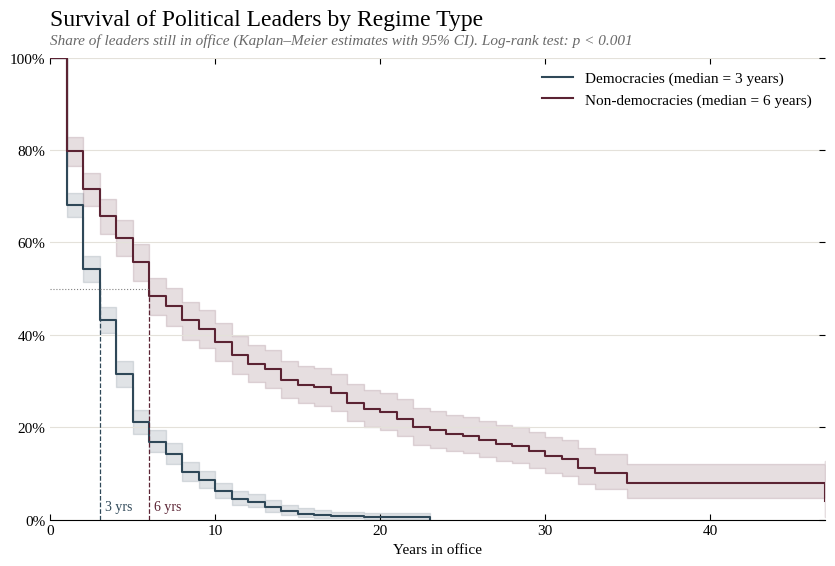

In [59]:
from lifelines.statistics import logrank_test

T, E = df["duration"], df["observed"]
dem = df["democracy"] == "Democracy"
fig, ax = plt.subplots(figsize=(10, 6))
medians = []

# One KM curve per group, with its median marked
for mask, name, color in [(dem, "Democracies", "#2f4858"), (~dem, "Non-democracies", "#5b2333")]:
    k = KaplanMeierFitter().fit(T[mask], E[mask])
    med = k.median_survival_time_
    medians.append(med)
    k.plot_survival_function(ax=ax, color=color, ci_alpha=0.15,
                             label=f"{name} (median = {med:.0f} years)")
    ax.plot([med, med], [0, 0.5], color=color, lw=0.9, ls="--")
    ax.text(med + 0.3, 0.02, f"{med:.0f} yrs", color=color, fontsize=10)

# 50% reference line, up to the larger median
ax.plot([0, max(medians)], [0.5, 0.5], color="gray", lw=0.8, ls=":")

# Log-rank test for the subtitle
p = logrank_test(T[dem], T[~dem], E[dem], E[~dem]).p_value

ax.set(xlim=(0, T.max()), ylim=(0, 1), xlabel="Years in office")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.grid(True)
ax.xaxis.grid(False)
ax.legend(frameon=False)
ax.set_title("Survival of Political Leaders by Regime Type\n", loc="left", fontsize=17)
ax.text(0, 1.03, "Share of leaders still in office (Kaplan–Meier estimates with 95% CI). "
        f"Log-rank test: p {'< 0.001' if p < 0.001 else f'= {p:.3f}'}",
        transform=ax.transAxes, style="italic", color="dimgray")
plt.show()

The Kaplan–Meier curves above show the estimated probability that a leader remains in office after t years (x-axis), comparing democracies and non-democracies. The data include 1,187 leader spells in democracies and 621 in non-democracies. At every point in time, leaders in non-democracies have a higher probability of remaining in office than leaders in democracies. The median time in office is 3 years for democratic leaders and 6 years for non-democratic leaders. After 20 years, an estimated 0.5% of democratic leaders remain in office, compared with 23% of non-democratic leaders.

#### Survival Summary: Democracy VS Non-Democracy

In [58]:
# Display survival summary
times = [1, 2, 5, 10, 15, 20]
tables = {}

for mask, name in [(dem, "Democracy"), (~dem, "Non-democracy")]:
    k = KaplanMeierFitter().fit(T[mask], E[mask])
    t = pd.concat([k.event_table["at_risk"], k.survival_function_, k.confidence_interval_], axis=1)
    t.columns = ["At risk", "Survival", "95% CI lower", "95% CI upper"]
    tables[name] = t.reindex(times, method="ffill").round(3)

pd.concat(tables, axis=1)

Democracy                                    Non-democracy           \
     At risk Survival 95% CI lower 95% CI upper       At risk Survival   
1       1187    0.682        0.654        0.707           621    0.799   
2        774    0.542        0.513        0.571           479    0.715   
5        302    0.211        0.186        0.236           330    0.558   
10        57    0.062        0.046        0.080           193    0.385   
15        10    0.013        0.006        0.024           114    0.292   
20         3    0.005        0.001        0.015            70    0.233   

                              
   95% CI lower 95% CI upper  
1         0.765        0.828  
2         0.678        0.749  
5         0.517        0.597  
10        0.343        0.426  
15        0.252        0.333  
20        0.194        0.274

 Leaders in non-democracies had a higher estimated probability of remaining in office at every time point. After one year, 80% of non-democratic leaders were still in office, compared with 68% of democratic leaders. The gap widened over time: after five years, 56% of non-democratic leaders remained versus 21% of democratic leaders, and after ten years, 39% versus 6%. By year 20, about 23% of non-democratic leaders were still in office, compared with less than 1% of democratic leaders. The 95% confidence intervals for the two groups do not overlap at any time point, which is consistent with the significant log-rank test.

#### **Log-rank test**

In [61]:
from lifelines.statistics import logrank_test

results = logrank_test(T[dem], T[~dem], E[dem], E[~dem], alpha=.99)

results.print_summary()


 A log-rank test showed that the survival curves of leaders in democracies and non-democracies differ significantly, χ²(1) = 260.47, p < 0.001. Leaders in non-democracies remained in office longer (median = 6 years) than leaders in democracies (median = 3 years), supporting the hypothesis.

### Cox-Proportional Hazards Methods

The Cox proportional hazards model is a regression method for survival data. It estimates how covariates affect the hazard, the risk that an event occurs at a given time among those still at risk, while accounting for censored cases. Each covariate’s effect is expressed as a hazard ratio: a value above 1 means a higher risk of the event (a shorter time to it), and a value below 1 means a lower risk (a longer time to it). The model does not require assumptions about how the baseline risk changes over time, but it does assume that each covariate’s effect on the hazard stays constant over time (the proportional hazards assumption).

In [67]:
# Format the data
cox_df = df[["duration", "observed", "ctryname"]].copy()
cox_df["democracy"] = (df["democracy"] == "Democracy").astype(int)   # 1 = Democracy, 0 = Non-democracy

# Fit the model
cph = CoxPHFitter()
cph.fit(cox_df, duration_col="duration", event_col="observed", cluster_col="ctryname")
cph.print_summary(style="ascii")

<lifelines.CoxPHFitter: fitted with 1808 total observations, 340 right-censored observations>
             duration col = 'duration'
                event col = 'observed'
              cluster col = 'ctryname'
          robust variance = True
      baseline estimation = breslow
   number of observations = 1808
number of events observed = 1468
   partial log-likelihood = -9614.27
         time fit was run = 2026-11-16 02:11:09 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
democracy  0.96      2.62      0.11            0.76            1.17                2.13                3.22

           cmp to    z      p  -log2(p)
covariate                              
democracy    0.00 9.11 <0.005     63.46
---
Concordance = 0.59
Partial AIC = 19230.53
log-likelihood ratio test = 264.03 on 1 df
-log2(p) of ll-ratio test 

A Cox proportional hazards model with standard errors clustered by country was used to estimate how regime type affects the hazard of leaving office. The hazard is the risk that a leader leaves office at a given point in time, among leaders who are still in office at that point. Leaders in democracies faced a significantly higher hazard of leaving office than leaders in non-democracies (HR = 2.62, 95% CI [2.13, 3.22], p < 0.001). At any given time, democratic leaders were about 2.6 times as likely to leave office as non-democratic leaders. The model’s concordance was 0.59, indicating that regime type alone modestly predicts which leaders leave office first.

### **Conclusion**

-----------------------


 The results support the hypothesis that leaders in non-democracies remain in office longer than leaders in democracies. Non-democratic leaders had a median time in office of 6 years, compared with 3 years for democratic leaders, and the difference between their survival curves was statistically significant (χ²(1) = 260.47, p < 0.001). A Cox proportional hazards model showed that democratic leaders faced 2.62 times the hazard of leaving office (95% CI [2.13, 3.22], p < 0.001). These results show an association rather than a causal effect.